16 ['0.00294', '0.000185', '2.29e-05', '7.63e-06']
32 ['0.0183', '0.000577', '5.72e-05', '1.91e-05']
64 ['0.106', '0.00166', '0.000137', '4.58e-05']
128 ['0.574', '0.0045', '0.00032', '0.000107']


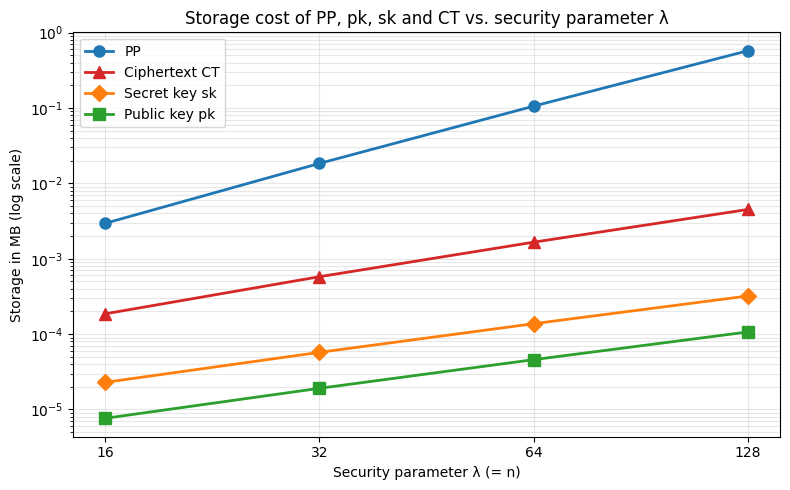

In [ ]:
import math
import matplotlib.pyplot as plt

# ---- parameters (assumptions) ----
N = 2**20          # total users (only enters PP through log2 N)
S = 16             # |S| (not needed for these four objects)
sigma, tau = 3.2, 6
MB = 8 * 2**20     # bits per MB (1 MB = 2^20 bytes)

def storage_mb(lam):
    n = lam
    w = math.ceil(math.log2(n))          # p = 2^w, bits per Z_p entry
    m = 3 * n * w
    # PP (lazy form): D, T_D (binary m x nw), u, seed varsigma, N
    pp = n*m*w + m*n*w + n*w + lam + math.ceil(math.log2(N))
    pk = n * w                           # d_i : n entries of Z_p
    sk = m                               # r_i : m bits
    ct = lam + (2*m + 1) * w             # varsigma, c0, c1, c2
    return [pp/MB, ct/MB, sk/MB, pk/MB]

lams = [16, 32, 64, 128]
vals = [storage_mb(l) for l in lams]
names = ["PP", "Ciphertext CT", "Secret key sk", "Public key pk"]
styles = [("tab:blue", "o"), ("tab:red", "^"), ("tab:orange", "D"), ("tab:green", "s")]

for l, v in zip(lams, vals):
    print(l, ["%.3g" % x for x in v])

x = list(range(len(lams)))
fig, ax = plt.subplots(figsize=(8, 5))
for idx, (name, (c, mk)) in enumerate(zip(names, styles)):
    ax.plot(x, [v[idx] for v in vals], color=c, marker=mk, markersize=8,
            linewidth=2, label=name)

ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels([str(l) for l in lams])
ax.set_xlabel("Security parameter λ (= n)")
ax.set_ylabel("Storage in MB (log scale)")
ax.set_title("Storage cost of PP, pk, sk and CT vs. security parameter λ")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("storage_vs_lambda.png", dpi=150)   # saves the file
plt.show()                                      # opens the graph window